# Fake Text Detection

This project aims to identify the real text in a pair of texts for the
Kaggle competition "Fake or Real: The Impostor Hunt in Texts".

## Dataset

- **Training set:** 95 text pairs stored in separate article folders.
  Each folder contains `file_1.txt` and `file_2.txt`.
- **Test set:** 1,068 text pairs with the same folder structure.
- **train.csv:** Contains the ground-truth labels for the training set:
  - `id`: The article folder identifier.
  - `real_text_id`: The number of the real text, either `1` or `2`.
Both texts in each pair have been modified using language models.
The real text better preserves the information in the hidden original
document, while the fake text deviates more from it.

## Goal

Given two texts from the same article folder, predict which one is real:

- Output `1` if `file_1.txt` is real.
- Output `2` if `file_2.txt` is real.

## Assignment 1: EDA and Baseline Models

Explore the dataset, examine text characteristics and label distributions,
and implement baseline models evaluated using pairwise accuracy.

In [10]:
import pandas as pd

# Load train.csv
train_csv = "/Users/tosun/Desktop/2026-2027 Güz Dersler/Data Science/data/raw/train.csv"
train_labels = pd.read_csv(train_csv)
print(train_labels.shape)
train_labels.head()


(95, 2)


,id,real_text_id
0,0,1
1,1,2
2,2,1
3,3,2
4,4,2


In [39]:
train_labels.info()

print(f"Result values: {train_labels['real_text_id'].unique()}")
print(f"Repeated IDs: {train_labels['id'].duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            95 non-null     int64
 1   real_text_id  95 non-null     int64
dtypes: int64(2)
memory usage: 1.6 KB
Result values: [1 2]
Repeated IDs: 0


- The dataset contains 95 samples and 2 columns (id and real_text_id), both of integer type (int64). There are no missing values or duplicate IDs. The target column (real_text_id) contains two unique values: 1 and 2, as expected.

In [54]:
from pathlib import Path
#our new df with csv info
train_dir = Path("/Users/tosun/Desktop/2026-2027 Güz Dersler/Data Science/data/raw/train")
rows = []

for _, row in train_labels.iterrows():
    article_id = int(row["id"])
    real_text_id = int(row["real_text_id"])

    article_dir = train_dir/f"article_{article_id:04d}"

    with open(article_dir / "file_1.txt", encoding="utf-8") as f:
        text_1 = f.read()

    with open(article_dir / "file_2.txt", encoding="utf-8") as f:
        text_2 = f.read()

    if real_text_id == 1:
        real_text = text_1
        fake_text = text_2
    else:
        real_text = text_2
        fake_text = text_1

    rows.append({
        "article_id": article_id,
        "real_text": real_text,
        "fake_text": fake_text,
        "real_text_id": real_text_id
    })


In [53]:
texts_df = pd.DataFrame(rows)

texts_df["real_text_length"] = texts_df["real_text"].str.len()
texts_df["fake_text_length"] = texts_df["fake_text"].str.len()
texts_df.head()


,article_id,real_text,fake_text,real_text_id,real_text_length,fake_text_length
0,0,The VIRSA (Visible Infrared Survey Telescope A...,The China relay network has released a signifi...,1,2196,2018
1,1,The project aims to achieve an accuracy level ...,China\nThe goal of this project involves achie...,2,936,3124
2,2,Scientists can learn about how galaxies form a...,Dinosaur eggshells offer clues about what dino...,1,1139,801
3,3,The importance for understanding how stars evo...,China\nThe study suggests that multiple star s...,2,1869,1774
4,4,Analyzing how fast stars rotate within a galax...,Dinosaur Rex was excited about his new toy set...,2,871,195


In [65]:
for column in ["real_text", "fake_text"]:
    empty_count = texts_df[column].str.strip().eq("").sum()
    print(column, "Empty Text", empty_count)

real_text Empty Text 0
fake_text Empty Text 0


In [ ]:
# Fix empty texts
texts_df = texts_df.loc[
    texts_df["real_text"].str.strip().ne("")
    & texts_df["fake_text"].str.strip().ne("")
].copy()

In [67]:
print(texts_df[["real_text_length", "fake_text_length"]].agg(["mean", "median"]))

(texts_df["real_text_length"] < texts_df["fake_text_length"]).value_counts()

        real_text_length  fake_text_length
mean         1439.236559       3495.268817
median       1368.000000       1905.000000


True     70
False    23
Name: count, dtype: int64

- We can see that real texts are generally shorter than fake texts in the training data. However, this does not mean that the real text is shorter in every pair.

In [77]:
texts_df["real_word_count"] = texts_df["real_text"].str.split().str.len()
texts_df["fake_word_count"] = texts_df["fake_text"].str.split().str.len()
texts_df.head()


,article_id,real_text,fake_text,real_text_id,real_text_length,fake_text_length,real_word_count,fake_word_count
0,0,The VIRSA (Visible Infrared Survey Telescope A...,The China relay network has released a signifi...,1,2196,2018,304,296
1,1,The project aims to achieve an accuracy level ...,China\nThe goal of this project involves achie...,2,936,3124,137,454
2,2,Scientists can learn about how galaxies form a...,Dinosaur eggshells offer clues about what dino...,1,1139,801,159,125
3,3,The importance for understanding how stars evo...,China\nThe study suggests that multiple star s...,2,1869,1774,262,263
4,4,Analyzing how fast stars rotate within a galax...,Dinosaur Rex was excited about his new toy set...,2,871,195,123,34


In [79]:
print(texts_df[["real_word_count", "fake_word_count"]].agg(["mean", "median"]))
(texts_df["real_word_count"] < texts_df["fake_word_count"]).value_counts()


        real_word_count  fake_word_count
mean         215.354839       437.258065
median       199.000000       289.000000


True     71
False    22
Name: count, dtype: int64

In [84]:
import re

def count_sentences(text):
    sentences = re.split(r"[.!?]+(?:\s+|$)", text.strip())
    return sum(bool(sentence.strip()) for sentence in sentences)

texts_df["real_sentence_count"] = texts_df["real_text"].apply(count_sentences)
texts_df["fake_sentence_count"] = texts_df["fake_text"].apply(count_sentences)


In [86]:
print(texts_df[["real_sentence_count", "fake_sentence_count"]].agg(["mean", "median"]))
(texts_df["real_sentence_count"] < texts_df["fake_sentence_count"]).value_counts()

        real_sentence_count  fake_sentence_count
mean               9.268817            11.795699
median             9.000000            11.000000


True     62
False    31
Name: count, dtype: int64

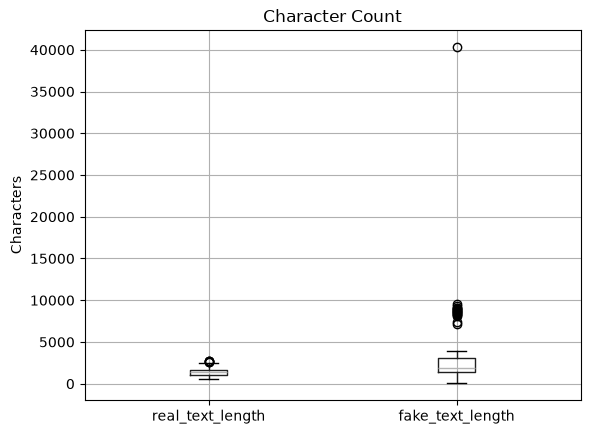

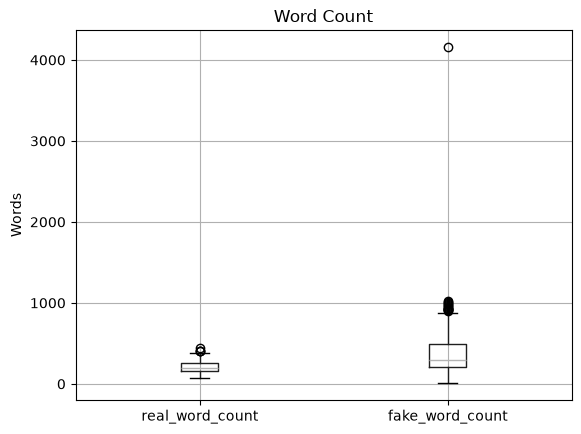

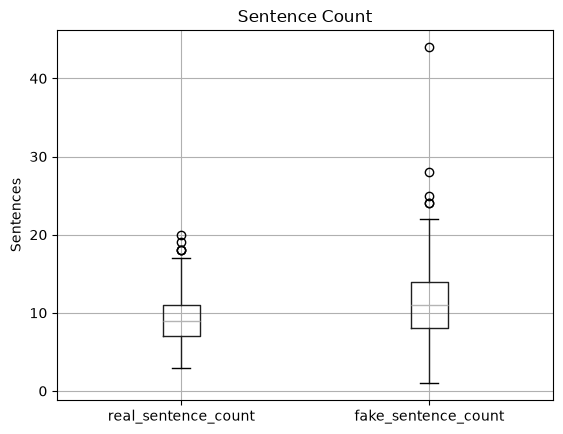

In [87]:
import matplotlib.pyplot as plt

#  text length
texts_df[["real_text_length", "fake_text_length"]].boxplot()
plt.title("Character Count")
plt.ylabel("Characters")
plt.show()

# word count
texts_df[["real_word_count", "fake_word_count"]].boxplot()
plt.title("Word Count")
plt.ylabel("Words")
plt.show()

# sentence count
texts_df[["real_sentence_count", "fake_sentence_count"]].boxplot()
plt.title("Sentence Count")
plt.ylabel("Sentences")
plt.show()

## Text Length Analysis

We compared character, word, and sentence counts for real and fake texts. Two pairs with empty fake texts were excluded, leaving 93 pairs.

- Fake texts have higher median character, word, and sentence counts.
- Real texts contain fewer words in 71 of the 93 pairs (76.3%).
- Fake text lengths vary more and include some very long examples.
- These extreme values help explain why the mean is higher than the median.
- The distributions overlap, so length alone cannot perfectly distinguish real and fake texts.